# Black–Litterman: A Model with a View
### Companion notebook for Part II

This notebook replicates the examples from Part II of series on the article on the Black-Litterman (BL) model on the [Systematically Biased Substack](https://substack.com/@systematicallybiased).

The notation follows [Part I](https://systematicallybiased.substack.com/p/black-litterman-a-model-with-a-view?r=6w89b). The Bayesian update is implemented with NumPy and SciPy first, and later the notebook illustrates how to reproduce the results using the PyPortfolioOpt and skfolio packages.

## 0. Configure the example

This notebook uses the weights of the global market portfolio computed previously and discussed in [Part II](https://systematicallybiased.substack.com/p/7d04c1d9-0e1e-4a30-8c8c-3fc3e2ea6b33?postPreview=paid&updated=2026-11-12T09%3A19%3A43.839Z&audience=only_paid&free_preview=false&freemail=). The benchmark weights are provided directly in the configuration cell below. They were calculated from the five selected indices' Bloomberg market values observed on October 30, 2026. The notebook downloads the ETF price history needed for covariance estimation.

Run the setup below before the analysis. Returns and weights are decimals in the code. Tables and charts label percentages explicitly.



### Run in Google Colab

Upload this notebook to [Google Colab](https://colab.research.google.com/) and connect to a CPU runtime. Run the setup cell below **by itself** first. If it installs packages, choose **Runtime → Restart session**, then **Runtime → Run all**. The setup cell skips installation once the requested versions are present. Only this notebook is needed. The benchmark weights are embedded, and ETF prices are downloaded from Yahoo Finance.

For local Jupyter, install the package versions listed in the setup cell before running the analysis. The setup cell leaves local environments untouched.

In [4]:
from importlib.metadata import PackageNotFoundError, version
from importlib.util import find_spec
import subprocess
import sys

# Analysis dependencies are listed here so the notebook is self-contained.
# Colab provides its own notebook kernel.
ANALYSIS_REQUIREMENTS = [
    "numpy==2.5.4",
    "pandas==3.1.1",
    "scipy==1.18.1",
    "scikit-learn==1.9.1",
    "matplotlib==3.11.2",
    "yfinance==1.8.0",
    "PyPortfolioOpt==1.6.0",
    "skfolio==1.12.13",
]

colab_restart_needed = False
if find_spec("google") is not None and find_spec("google.colab") is not None:
    def installed_version(package):
        try:
            return version(package)
        except PackageNotFoundError:
            return None

    needs_install = any(
        installed_version(name) != pinned
        for name, pinned in (spec.split("==") for spec in ANALYSIS_REQUIREMENTS)
    )
    if needs_install:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--quiet", *ANALYSIS_REQUIREMENTS],
            check=True,
        )
        colab_restart_needed = True
        print("Packages installed. Choose Runtime → Restart session, then Runtime → Run all.")
    else:
        print("Colab dependencies are ready.")


Colab dependencies are ready.


In [5]:
if globals().get("colab_restart_needed", False):
    raise RuntimeError("Restart the Colab session, then run all cells.")

from importlib.metadata import version
from pathlib import Path
from datetime import datetime, timezone
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from IPython.display import display
from scipy.linalg import solve
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

TICKERS = ["VTI", "IDEV", "IEMG", "BND", "BNDX"]
BENCHMARK_AS_OF = "2026-10-30"
# Bloomberg index market values (IN089 equities, BX200 bonds), October 30, 2026.
# Weights retain full precision from the internal GMP construction.
# Edit these weights and BENCHMARK_AS_OF together for another allocation.
WEIGHTS = pd.Series({
    "VTI":  0.41701537478994094,
    "IDEV": 0.16304112699990386,
    "IEMG": 0.07376444951436788,
    "BND":  0.1710138101772214,
    "BNDX": 0.1751652385185659,
}, name="Benchmark weight")
benchmark_source = "Bloomberg index market values (IN089 and BX200); embedded October 2026 snapshot"
AS_OF = "2026-10-31"

# inputs for the example
ASSUMED_PREMIUM = .04       # Annual expected excess return of the whole benchmark
ANNUAL_TRADING_DAYS = 252
COVARIANCE_METHOD = "sample"  # or "ledoit_wolf" for a shrinkage comparison
TAU = .025

# manager's views
VIEW_RETURN = {"V1": .0050, "V2": .08, "V3": .01, "V4": .03}
CONFIDENCE = {"V1": .75, "V2": .60, "V3": .70, "V4": .50}

USE_CACHE = False
OUT = Path("bl_etf_outputs")
CACHE = OUT / "provider_cache"
SAVE_FIGURES = True
ATOL = 1e-10

if not WEIGHTS.index.is_unique or set(WEIGHTS.index) != set(TICKERS):
    raise ValueError("Provide exactly one benchmark weight for each configured ETF.")
WEIGHTS = pd.to_numeric(WEIGHTS).reindex(TICKERS)
if not np.isfinite(WEIGHTS).all() or not (WEIGHTS > 0).all() or not np.isclose(
    WEIGHTS.sum(), 1, atol=ATOL, rtol=0
):
    raise ValueError("The five positive benchmark weights must sum to one.")
print(f"Benchmark weights as of {BENCHMARK_AS_OF} | {benchmark_source}")
display(WEIGHTS.to_frame("Benchmark weight").style.format("{:.2%}"))
assert 0 < TAU <= 1 and ASSUMED_PREMIUM > 0 and ANNUAL_TRADING_DAYS > 0
assert COVARIANCE_METHOD in {"ledoit_wolf", "sample"}
OUT.mkdir(exist_ok=True)

versions = {"Python": platform.python_version()}
for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib",
             "yfinance", "PyPortfolioOpt", "skfolio"]:
    versions[name] = version(name)
display(pd.Series(versions, name="Version").to_frame())

def show_figure(fig, filename):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(OUT / filename, dpi=180, bbox_inches="tight")
    plt.show()

Benchmark weights as of 2026-10-30 | Bloomberg index market values (IN089 and BX200); embedded October 2026 snapshot


,Benchmark weight
VTI,41.70%
IDEV,16.30%
IEMG,7.38%
BND,17.10%
BNDX,17.52%


,Version
Python,3.13.18
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
yfinance,1.8.0
PyPortfolioOpt,1.6.0
skfolio,1.12.13


## 1. What expected returns make the benchmark optimal?

We estimate $\Sigma$ from five years of daily simple USD returns through the configured cutoff and annualize by 252. The baseline uses the **sample covariance matrix**. About 1,250 daily observations support this five-asset estimate. Ledoit–Wolf shrinkage toward a **scaled identity** remains available as an alternative, estimated over the same days. The independent covariance cutoff lets you change the embedded benchmark weights and their date independently of the risk estimate.

Yahoo Finance supplies split- and dividend-adjusted closing prices in USD. We align the five ETFs on common observation dates and compute daily simple returns. Historical portfolio performance is covered in the GMP construction notebook.

Treating the benchmark as an unconstrained mean–variance optimum and its annual excess premium $m_{mkt}$ as an assumption gives

$$
\sigma_{mkt}^2=w_{mkt}^{\top}\Sigma w_{mkt},\qquad
\beta=\frac{\Sigma w_{mkt}}{\sigma_{mkt}^2},\qquad
\lambda=\frac{m_{mkt}}{\sigma_{mkt}^2},\qquad
\pi=\lambda\Sigma w_{mkt}=m_{mkt}\beta.
$$

These are CAPM-style betas against our five-ETF proxy. They measure exposure to that portfolio; they do not identify the true global market portfolio.

In [6]:
price_cache = CACHE / "adjusted_daily_prices.csv"
stamp_cache = CACHE / "download.json"

if USE_CACHE:
    if not all(path.exists() for path in (price_cache, stamp_cache)):
        raise FileNotFoundError("No local provider cache. Run once with USE_CACHE = False.")
    prices_all = pd.read_csv(price_cache, index_col=0, parse_dates=True)
    download = json.loads(stamp_cache.read_text())
else:
    try:
        yf.set_tz_cache_location(str(CACHE / "yfinance"))
        raw = yf.download(
            tickers=TICKERS, period="max", auto_adjust=True, actions=False,
            progress=False, threads=False, group_by="column", timeout=25,
        )
        prices_all = raw["Close"]
        if not set(TICKERS).issubset(prices_all.columns) or prices_all.isna().all().any():
            raise ValueError("Yahoo Finance did not return all five price series")
    except Exception as exc:
        raise RuntimeError(
            "Live data unavailable. Check Yahoo Finance access and rerun, "
            "or set USE_CACHE = True if you already have a local cache."
        ) from exc
    download = {"downloaded_utc": datetime.now(timezone.utc).isoformat(),
                "prices": "Yahoo Finance adjusted close"}

prices_all = prices_all.loc[:, TICKERS].sort_index().dropna(how="all")
prices_all.index = pd.to_datetime(prices_all.index).tz_localize(None).normalize()
inception = pd.DataFrame({
    "First available": prices_all.apply(pd.Series.first_valid_index),
    "Last available": prices_all.apply(pd.Series.last_valid_index),
})
prices = prices_all.dropna()
as_of = pd.Timestamp(AS_OF)
# The last trading-day observation can precede the calendar cutoff.
if prices.empty or prices.index.max() < as_of - pd.Timedelta(days=4):
    raise ValueError("The shared ETF data do not reach the covariance cutoff.")

if not USE_CACHE:
    CACHE.mkdir(parents=True, exist_ok=True)
    prices_all.to_csv(price_cache)
    stamp_cache.write_text(json.dumps(download, indent=2))

print(f"Source: {'local cache' if USE_CACHE else 'live'}; downloaded {download['downloaded_utc']}")
print(f"Common adjusted-price coverage: {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d}")
display(inception)
daily_returns = prices.pct_change(fill_method=None).dropna()

Source: live; downloaded 2026-11-26T13:54:35.042903+00:00
Common adjusted-price coverage: 2017-03-27 to 2026-11-25


,First available,Last available
Ticker,,
VTI,2001-06-15,2026-11-25
IDEV,2017-03-27,2026-11-25
IEMG,2012-10-24,2026-11-25
BND,2007-04-10,2026-11-25
BNDX,2013-06-04,2026-11-25


In [7]:
window_start = as_of - pd.DateOffset(years=5)
window = daily_returns.loc[(daily_returns.index > window_start) & (daily_returns.index <= as_of)]
if len(window) < 1000 or window.index.min() > window_start + pd.Timedelta(days=7):
    raise ValueError("The aligned history does not cover the five-year covariance window.")

sigma_sample = window.cov() * ANNUAL_TRADING_DAYS
sigma_lw = pd.DataFrame(
    LedoitWolf().fit(window.to_numpy()).covariance_ * ANNUAL_TRADING_DAYS,
    index=TICKERS, columns=TICKERS,
)
covariance = {"ledoit_wolf": sigma_lw, "sample": sigma_sample}[COVARIANCE_METHOD]
Sigma = covariance.to_numpy()
w_mkt = WEIGHTS.to_numpy()[:, None]
assert Sigma.shape == (len(TICKERS), len(TICKERS))
np.testing.assert_allclose(Sigma, Sigma.T, atol=ATOL, rtol=0)
assert np.linalg.eigvalsh(Sigma).min() > 0

In [8]:
market_variance = (w_mkt.T @ Sigma @ w_mkt).item()
beta = Sigma @ w_mkt / market_variance
risk_aversion = ASSUMED_PREMIUM / market_variance
pi = risk_aversion * Sigma @ w_mkt

np.testing.assert_allclose(w_mkt.T @ beta, 1, atol=ATOL, rtol=0)
np.testing.assert_allclose(w_mkt.T @ pi, ASSUMED_PREMIUM, atol=ATOL, rtol=0)
np.testing.assert_allclose(pi, ASSUMED_PREMIUM * beta, atol=ATOL, rtol=0)

equilibrium = pd.DataFrame({
    "benchmark_weight": WEIGHTS,
    "annual_volatility": np.sqrt(np.diag(Sigma)),
    "beta": beta.ravel(),
    "prior_annual_excess_return": pi.ravel(),
})
print(f"{COVARIANCE_METHOD}: {len(window):,} daily returns, "
      f"{window.index.min():%Y-%m-%d} to {window.index.max():%Y-%m-%d}")
print(f"Benchmark volatility: {market_variance**.5:.2%} | "
      f"Assumed premium: {ASSUMED_PREMIUM:.2%} | Risk aversion: {risk_aversion:.4f}")
display(equilibrium.style.format({
    "benchmark_weight": "{:.1%}", "annual_volatility": "{:.2%}",
    "beta": "{:.3f}", "prior_annual_excess_return": "{:.2%}",
}))
display(covariance.style.format("{:.5f}"))

sample: 1,255 daily returns, 2021-11-01 to 2026-10-30
Benchmark volatility: 11.31% | Assumed premium: 4.00% | Risk aversion: 3.1274


,benchmark_weight,annual_volatility,beta,prior_annual_excess_return
VTI,41.7%,17.49%,1.487,5.95%
IDEV,16.3%,16.35%,1.318,5.27%
IEMG,7.4%,19.51%,1.382,5.53%
BND,17.1%,6.07%,0.211,0.84%
BNDX,17.5%,4.92%,0.154,0.62%


Ticker,VTI,IDEV,IEMG,BND,BNDX
Ticker,,,,,
VTI,0.03060,0.02341,0.02390,0.00233,0.00161
IDEV,0.02341,0.02673,0.02551,0.00294,0.00197
IEMG,0.02390,0.02551,0.03805,0.00253,0.00180
BND,0.00233,0.00294,0.00253,0.00368,0.00246
BNDX,0.00161,0.00197,0.00180,0.00246,0.00242


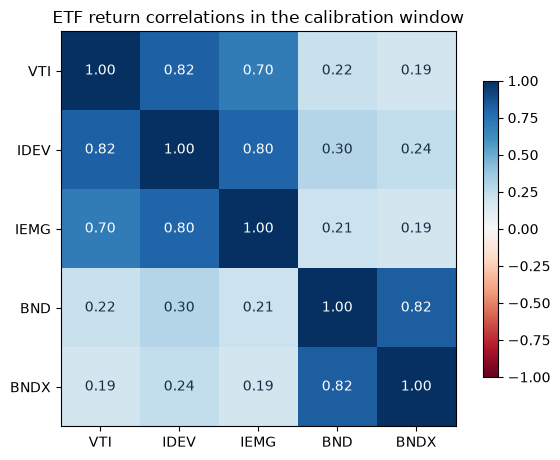

In [9]:
vol = np.sqrt(np.diag(Sigma))
correlation = Sigma / np.outer(vol, vol)
fig, ax = plt.subplots(figsize=(6.1, 4.7))
heatmap = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu")
ax.set(xticks=range(len(TICKERS)), yticks=range(len(TICKERS)),
       xticklabels=TICKERS, yticklabels=TICKERS, title="ETF return correlations in the calibration window")
for i, row in enumerate(correlation):
    for j, corr in enumerate(row):
        ax.text(j, i, f"{corr:.2f}", ha="center", va="center",
                color="white" if abs(corr) > .65 else "#162e43")
fig.colorbar(heatmap, ax=ax, shrink=.75)
show_figure(fig, "etf_correlations.png")

The market-weighted beta is 1, so the market-weighted prior returns reproduce $m_{mkt}$. Now we can ask how far a view moves us away from that anchor.

## 2. Update the prior by hand: one view with proportional uncertainty

Let $\mu\sim N(\pi,\tau\Sigma)$ and $q\mid\mu\sim N(P\mu,\Omega)$. Row $p_k$ picks the assets in view $k$; the matching entry of $q$ states its annual expected excess return or excess-return spread. Each cell uses the same ticker order.

$$
\begin{aligned}
\mu\mid q &\sim N(\mu_{BL},\Sigma_{BL}),\\
\mu_{BL} &= \pi + \tau\Sigma P^\top(P\tau\Sigma P^\top+\Omega)^{-1}(q-P\pi),\\
\Sigma_{BL} &= \left[(\tau\Sigma)^{-1}+P^\top\Omega^{-1}P\right]^{-1}.
\end{aligned}
$$

The update is driven by the **innovation** $q-P\pi$, the difference between the view and the benchmark's implied view. $\Sigma_{BL}$ measures uncertainty about expected returns. Adding $\Sigma$ gives the predictive covariance of realized returns.

We solve the smaller system in view space and compute the covariance as
$\tau\Sigma-\tau\Sigma P^\top(P\tau\Sigma P^\top+\Omega)^{-1}P\tau\Sigma$.
The precision-space formula above requires invertible $\Omega$; the view-space system also works for exact, independent hard views with zero view-error variance.

In [10]:
def check_close(actual, expected):
    np.testing.assert_allclose(actual, expected, atol=ATOL, rtol=0)

In [11]:
def long_only(mean):
    expected = mean.ravel()
    def loss(w):
        return .5 * risk_aversion * (w @ Sigma @ w) - w @ expected
    def gradient(w):
        return risk_aversion * (Sigma @ w) - expected

    result = minimize(
        loss, w_mkt.ravel(), jac=gradient, method="SLSQP",
        bounds=[(0, 1)] * len(TICKERS),
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1,
                     "jac": lambda w: np.ones_like(w)},
        options={"ftol": 1e-13, "maxiter": 500},
    )
    if not result.success:
        raise RuntimeError(result.message)
    check_close(result.x.sum(), 1)
    assert result.x.min() >= -ATOL
    return result

All allocations in this tutorial maximize expected excess return minus the variance penalty, subject to nonnegative weights and full investment:

$$
\max_w\; w^\top\mu-\frac{\lambda}{2}w^\top\Sigma w,
\qquad \mathbf{1}^\top w=1,\quad w\geq0.
$$

We use this same objective and the baseline $\Sigma$ for the single-view example and the four-view portfolio.

In [12]:
def bl_posterior(prior_returns, covariance, view_matrix, view_returns, tau, view_uncertainty):
    prior_uncertainty = tau * covariance
    if len(view_matrix) == 0:
        return prior_returns.copy(), prior_uncertainty
    cross_covariance = prior_uncertainty @ view_matrix.T
    view_system = view_matrix @ cross_covariance + view_uncertainty
    innovation = view_returns - view_matrix @ prior_returns
    posterior_returns = prior_returns + cross_covariance @ solve(view_system, innovation, assume_a="pos")
    posterior_uncertainty = prior_uncertainty - cross_covariance @ solve(
        view_system, cross_covariance.T, assume_a="pos"
    )
    return posterior_returns, posterior_uncertainty

def proportional_omega(view_matrix, covariance, tau):
    view_variances = np.diag(view_matrix @ covariance @ view_matrix.T)
    assert (view_variances > 0).all()
    return tau * np.diag(view_variances)

Start with Beatrice's relative view: developed ex-US equities (IDEV) outperform US equities (VTI). Let $D=\operatorname{diag}(\operatorname{diag}(P\Sigma P^\top))$ and $\Omega=\tau D$. By keeping only the diagonal, we assume independent **view errors**; that does not imply that the returns on the view portfolios are independent.

In [13]:
p1 = np.array([[-1., 1., 0., 0., 0.]])
q1 = np.array([[VIEW_RETURN["V1"]]])
omega1 = proportional_omega(p1, Sigma, TAU)
D1 = omega1 / TAU
mean1, uncertainty1 = bl_posterior(pi, Sigma, p1, q1, TAU, omega1)

assert p1.shape == (1, len(TICKERS)) and q1.shape == (1, 1)
display(pd.DataFrame(p1, index=["V1"], columns=TICKERS))
display(pd.DataFrame({
    "q": q1.ravel(), "P @ pi": (p1 @ pi).ravel(), "innovation": (q1 - p1 @ pi).ravel(),
    "D (variance)": np.diag(D1), "Omega (variance)": np.diag(omega1),
}, index=["V1"]).style.format({
    "q": "{:.2%}", "P @ pi": "{:.2%}", "innovation": "{:+.2%}",
    "D (variance)": "{:.6g}", "Omega (variance)": "{:.6g}",
}))

single_solution = long_only(mean1)
w1 = single_solution.x
single_view_table = pd.DataFrame({
    "Prior excess return": pi.ravel(), "Posterior excess return": mean1.ravel(),
    "Benchmark weight": WEIGHTS, "Risky allocation": w1, "Active weight": w1 - WEIGHTS,
}, index=TICKERS)
display(single_view_table.style.format("{:.2%}"))
print(f"Total risky weight: {w1.sum():.2%} | Cash: {1 - w1.sum():.2%}")
print("Long-only solver:", single_solution.message)

,VTI,IDEV,IEMG,BND,BNDX
V1,-1.0,1.0,0.0,0.0,0.0


,q,P @ pi,innovation,D (variance),Omega (variance)
V1,0.50%,-0.68%,+1.18%,0.0105002,0.000262505


,Prior excess return,Posterior excess return,Benchmark weight,Risky allocation,Active weight
VTI,5.95%,5.55%,41.70%,23.76%,-17.94%
IDEV,5.27%,5.46%,16.30%,34.24%,17.94%
IEMG,5.53%,5.62%,7.38%,7.38%,-0.00%
BND,0.84%,0.88%,17.10%,17.10%,-0.00%
BNDX,0.62%,0.64%,17.52%,17.52%,0.00%


Total risky weight: 100.00% | Cash: -0.00%
Long-only solver: Optimization terminated successfully


The posterior expected IDEV–VTI spread lies halfway between the prior-implied spread and the manager's target under $\Omega=\tau D$. Correlations transmit revisions to the expected returns of other ETFs. The allocation table reports the fully invested long-only optimum.

## 3. Give Beatrice control over confidence

For an isolated view, confidence controls the fraction of the perfect-confidence expected-return revision incorporated into the posterior. Set the multiplier of that revision to the desired confidence using the Walters–Idzorek calibration.

With $v_k=p_k\Sigma p_k^\top$, the single-view update multiplies the perfect-confidence change by $1/(1+\omega_k/(\tau v_k))$. Equate that multiplier to $c_k$ to obtain the Walters closed form:

$$
\omega_k=\tau\frac{1-c_k}{c_k}v_k,\qquad
\mu_{k,100}=\pi+\frac{\Sigma p_k^\top}{v_k}(q_k-p_k\pi).
$$

In [14]:
def idzorek_inputs(view_matrix, view_returns, confidences, covariance, tau):
    assert view_matrix.shape == (len(confidences), len(covariance))
    assert view_returns.shape == (len(confidences), 1)
    assert np.all((0 <= confidences) & (confidences <= 1))
    keep = confidences > 0
    active_views = view_matrix[keep]
    active_confidence = confidences[keep]
    view_variances = np.diag(active_views @ covariance @ active_views.T)
    omega = tau * np.diag((1 - active_confidence) / active_confidence * view_variances)
    return active_views, view_returns[keep], omega

def confidence_posterior(view_matrix, view_returns, confidences):
    active_P, active_q, omega = idzorek_inputs(view_matrix, view_returns, confidences, Sigma, TAU)
    return bl_posterior(pi, Sigma, active_P, active_q, TAU, omega)

Confidence calibrates each view's uncertainty using the Walters–Idzorek rule. At 0% we omit the view. At 100% its error variance is zero and the posterior imposes the view exactly. The confidence percentage scales the isolated expected-return adjustment linearly. Long-only allocations can depart from that linear pattern when a weight reaches its bound.

,posterior view spread,VTI,IDEV,IEMG,BND,BNDX,risky weight sum
confidence,,,,,,,
0%,-0.68%,0.00%,0.00%,0.00%,0.00%,0.00%,100.00%
10%,-0.56%,-3.59%,3.59%,-0.00%,-0.00%,0.00%,100.00%
20%,-0.44%,-7.18%,7.18%,-0.00%,-0.00%,0.00%,100.00%
30%,-0.32%,-10.76%,10.76%,-0.00%,-0.00%,0.00%,100.00%
40%,-0.21%,-14.35%,14.35%,-0.00%,-0.00%,0.00%,100.00%
50%,-0.09%,-17.94%,17.94%,-0.00%,-0.00%,0.00%,100.00%
60%,0.03%,-21.53%,21.53%,-0.00%,-0.00%,0.00%,100.00%
70%,0.15%,-25.12%,25.12%,-0.00%,-0.00%,0.00%,100.00%
80%,0.26%,-28.70%,28.70%,-0.00%,-0.00%,0.00%,100.00%


ETF columns show long-only active weights versus the benchmark.


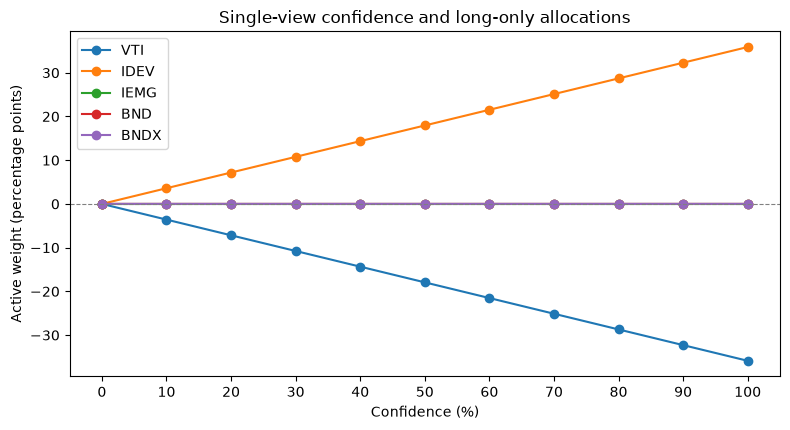

In [15]:
v1 = (p1 @ Sigma @ p1.T).item()
perfect_mean = pi + (Sigma @ p1.T / v1) @ (q1 - p1 @ pi)
grid = np.linspace(0, 1, 11)
confidence_rows = []
for confidence in grid:
    mean, uncertainty = confidence_posterior(p1, q1, np.array([confidence]))
    check_close(mean, pi + confidence * (perfect_mean - pi))
    w = long_only(mean).x
    confidence_rows.append([confidence, (p1 @ mean).item(),
                            *(w - w_mkt.ravel()), w.sum()])

confidence_table = pd.DataFrame(confidence_rows, columns=[
    "confidence", "posterior view spread", *TICKERS, "risky weight sum"
]).set_index("confidence")
display(confidence_table.style.format("{:.2%}").format_index("{:.0%}"))
print("ETF columns show long-only active weights versus the benchmark.")

fig, ax = plt.subplots(figsize=(8, 4.4))
for ticker in TICKERS:
    ax.plot(grid * 100, confidence_table[ticker] * 100, "o-", label=ticker)
ax.axhline(0, color="0.5", linestyle="--", linewidth=.8)
ax.set(xticks=grid * 100, xlabel="Confidence (%)",
       ylabel="Active weight (percentage points)",
       title="Single-view confidence and long-only allocations")
ax.legend()
show_figure(fig, "view1_confidence_tilts.png")

## 4. Four views at the manager's confidence levels

Now combine all four views using confidences of 75%, 60%, 70% and 50%. Each row of $P$ defines a view portfolio, with the equity and bond sleeve coefficients derived from the benchmark weights. The diagonal uncertainty entries use

$$\omega_k=\tau\frac{1-c_k}{c_k}\,p_k\Sigma p_k^\top.$$

The views interact through $P\Sigma P^\top$. After updating the expected returns jointly, solve the same fully invested long-only portfolio problem.

In [17]:
equity = WEIGHTS.loc[["VTI", "IDEV", "IEMG"]]
bonds = WEIGHTS.loc[["BND", "BNDX"]]
p4 = pd.concat([equity / equity.sum(), -bonds / bonds.sum()]).reindex(TICKERS)
P = np.vstack([p1, [0, 0, 1, 0, 0], [0, 0, 0, 1, -1], p4.to_numpy()])
view_names = ["V1", "V2", "V3", "V4"]
q = np.array([VIEW_RETURN[name] for name in view_names])[:, None]
view_confidence = np.array([CONFIDENCE[name] for name in view_names])
active_P, active_q, joint_omega = idzorek_inputs(P, q, view_confidence, Sigma, TAU)
view_variance = P @ Sigma @ P.T
view_table = pd.DataFrame(P, index=view_names, columns=TICKERS)
view_table.insert(0, "description", [
    "IDEV minus VTI", "IEMG excess return", "BND minus BNDX", "Equity sleeve minus bond sleeve"
])
view_table["q"] = q.ravel()
view_table["P @ pi"] = (P @ pi).ravel()
view_table["innovation"] = (q - P @ pi).ravel()
view_table["confidence"] = view_confidence
view_table["omega"] = np.nan  # Missing means the view was omitted.
view_table.loc[view_confidence > 0, "omega"] = np.diag(joint_omega)
display(view_table.style.format({
    **dict.fromkeys(TICKERS, "{:+.4f}"), "q": "{:.2%}", "P @ pi": "{:.2%}",
    "innovation": "{:+.2%}", "confidence": "{:.0%}", "omega": "{:.6g}",
}, na_rep="Omitted"))

,description,VTI,IDEV,IEMG,BND,BNDX,q,P @ pi,innovation,confidence,omega
V1,IDEV minus VTI,-1.0000,+1.0000,+0.0000,+0.0000,+0.0000,0.50%,-0.68%,+1.18%,75%,8.75017e-05
V2,IEMG excess return,+0.0000,+0.0000,+1.0000,+0.0000,+0.0000,8.00%,5.53%,+2.47%,60%,0.000634199
V3,BND minus BNDX,+0.0000,+0.0000,+0.0000,+1.0000,-1.0000,1.00%,0.23%,+0.77%,70%,1.27484e-05
V4,Equity sleeve minus bond sleeve,+0.6378,+0.2494,+0.1128,-0.4940,-0.5060,3.00%,5.00%,-2.00%,50%,0.00063615


In [18]:
mean4, uncertainty4 = confidence_posterior(P, q, view_confidence)
solution = long_only(mean4)
four_view_table = pd.DataFrame({
    "Prior excess return": pi.ravel(),
    "Posterior excess return": mean4.ravel(),
    "Benchmark weight": WEIGHTS,
    "Risky allocation": solution.x,
    "Active weight": solution.x - WEIGHTS.to_numpy(),
}, index=TICKERS)
display(four_view_table.style.format("{:.2%}"))
print("Long-only solver:", solution.message)
print(f"Total risky weight: {solution.x.sum():.2%}")

,Prior excess return,Posterior excess return,Benchmark weight,Risky allocation,Active weight
VTI,5.95%,5.59%,41.70%,8.47%,-33.23%
IDEV,5.27%,5.91%,16.30%,31.64%,15.34%
IEMG,5.53%,6.57%,7.38%,20.99%,13.62%
BND,0.84%,1.58%,17.10%,38.90%,21.80%
BNDX,0.62%,0.80%,17.52%,0.00%,-17.52%


Long-only solver: Optimization terminated successfully
Total risky weight: 100.00%


,Risky weight sum,Expected excess return (four-view posterior),Volatility (baseline Sigma),Concentration (HHI),Effective risky holdings
Benchmark,100.00%,4.19%,11.31%,0.266,3.76
Long-only BL,100.00%,4.34%,10.92%,0.303,3.30


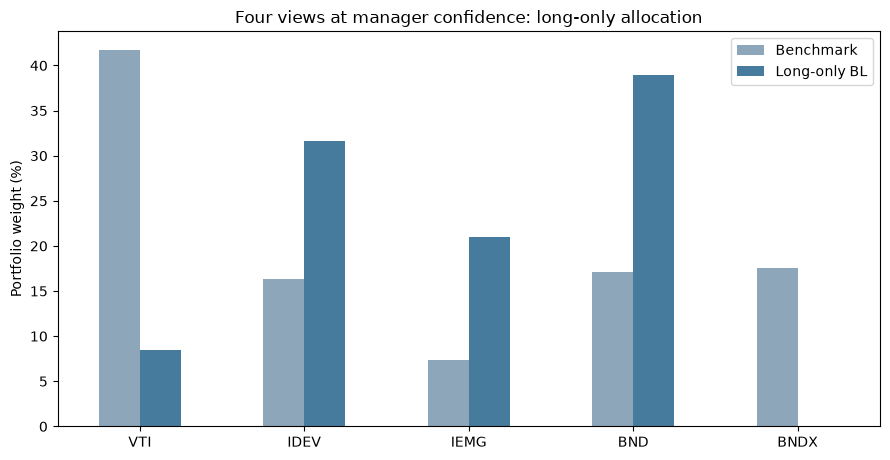

In [19]:
allocations = pd.DataFrame({"Benchmark": WEIGHTS, "Long-only BL": solution.x}, index=TICKERS)
active_weights = allocations.subtract(allocations["Benchmark"], axis=0)
portfolio_summary = pd.DataFrame({
    "Risky weight sum": allocations.sum(),
    "Expected excess return (four-view posterior)": allocations.T @ mean4.ravel(),
    "Volatility (baseline Sigma)": allocations.apply(lambda w: np.sqrt(w @ Sigma @ w)),
    "Concentration (HHI)": allocations.pow(2).sum(),
})
portfolio_summary["Effective risky holdings"] = 1 / portfolio_summary["Concentration (HHI)"]
display(portfolio_summary.style.format({
    "Risky weight sum": "{:.2%}", "Expected excess return (four-view posterior)": "{:.2%}",
    "Volatility (baseline Sigma)": "{:.2%}", "Concentration (HHI)": "{:.3f}",
    "Effective risky holdings": "{:.2f}",
}))
fig, ax = plt.subplots(figsize=(9, 4.7))
(allocations * 100).plot.bar(ax=ax, rot=0, color=["#8da6ba", "#477b9d"])
ax.set(xlabel="", ylabel="Portfolio weight (%)", title="Four views at manager confidence: long-only allocation")
show_figure(fig, "four_view_allocations.png")

### Numerical checks

Check that an absent view recovers the prior, a view equal to the prior leaves the mean unchanged, and a perfect-confidence view holds exactly. Check that the benchmark is recovered by the long-only optimizer under the equilibrium prior. The package replications below compare posterior moments and long-only allocations.

In [20]:
no_views_mean, no_views_cov = confidence_posterior(P, q, np.zeros(len(P)))
check_close(no_views_mean, pi)
check_close(no_views_cov, TAU * Sigma)
np.testing.assert_allclose(long_only(no_views_mean).x, w_mkt.ravel(), atol=1e-7, rtol=0)
matched_mean, _ = bl_posterior(pi, Sigma, P, P @ pi, TAU, proportional_omega(P, Sigma, TAU))
check_close(matched_mean, pi)
hard_mean, hard_cov = confidence_posterior(p1, q1, np.array([1.]))
check_close(hard_mean, perfect_mean)
check_close(p1 @ hard_mean, q1)
check_close(p1 @ hard_cov @ p1.T, np.zeros((1, 1)))
half_mean, half_cov = confidence_posterior(p1, q1, np.array([.5]))
check_close(half_mean, mean1)
check_close(half_cov, uncertainty1)
for matrix in [uncertainty1, uncertainty4]:
    check_close(matrix, matrix.T)
    assert np.linalg.eigvalsh(matrix).min() >= -ATOL
assert solution.success and solution.x.min() >= -ATOL
check_close(solution.x.sum(), 1)
print("Manual posterior and long-only allocation checks passed.")

Manual posterior and long-only allocation checks passed.


## 5. Replicate with PyPortfolioOpt and skfolio

Here we replicate the posterior excess-return and predictive-covariance calculations for the four views at the manager’s confidence levels using PyPortfolioOpt and skfolio. Both implementations use equivalent equilibrium priors, covariance estimates, views, and confidence levels.

PyPortfolioOpt implements the model through the `BlackLittermanModel` class in its `black_litterman` module. We supply the annual inputs $\pi$, $\Sigma$, $P$, $q$, and $\tau$ directly, and select `omega="idzorek"` to calibrate view uncertainty from the confidence levels. The `bl_returns()` method provides the posterior expected returns, while `bl_cov()` provides the predictive covariance. See the [PyPortfolioOpt documentation](https://pyportfolioopt.readthedocs.io/en/latest/BlackLitterman.html).

In skfolio, `skfolio.prior.BlackLitterman` follows an estimator-based interface and accepts views as expressions involving asset names. We use `EmpiricalPrior`, `EquilibriumMu`, and `EmpiricalCovariance` to reproduce our sample covariance and equilibrium prior using the same benchmark weights and risk-aversion coefficient. Because the estimator receives daily returns, we divide the annual view targets by 252. After fitting, we multiply the posterior means and predictive covariance by 252 to compare them with our annual manual calculations. These outputs are available through `return_distribution_.mu` and `return_distribution_.covariance`. See the [skfolio documentation](https://skfolio.org/generated/skfolio.prior.BlackLitterman.html).

Both packages also offer several alternatives for estimating $\Sigma$. PyPortfolioOpt’s `risk_models` module includes sample covariance, exponentially weighted covariance, and shrinkage estimators such as Ledoit–Wolf and Oracle Approximating Shrinkage. We can compute the chosen covariance matrix first and pass it to `BlackLittermanModel`. In skfolio, covariance estimation is integrated through estimator objects, including `EmpiricalCovariance`, `EWCovariance`, `LedoitWolf`, and `OAS`. These can be supplied to the prior estimator and to `EquilibriumMu`. When changing the estimator, we should use the same covariance specification for equilibrium calibration and the BL update, maintaining consistent return frequencies and annualization. See the [PyPortfolioOpt risk-model documentation](https://pyportfolioopt.readthedocs.io/en/latest/RiskModels.html) and [skfolio covariance estimators](https://skfolio.org/api/moments.html).

Both implementations return the predictive covariance, $\Sigma+\Sigma_{BL}$. Subtracting the original $\Sigma$ gives the posterior uncertainty about expected returns, $\Sigma_{BL}$, used in our notation. The tables below compare posterior expected excess returns and annual predictive covariance matrices across the three approaches.

In [21]:
# Replication using PyPortfolioOpt — annual inputs
from pypfopt import BlackLittermanModel

bl_pypfopt = BlackLittermanModel(
    cov_matrix=covariance,
    pi=pi,
    P=P,
    Q=q,
    tau=TAU,
    omega="idzorek",
    view_confidences=view_confidence,
)


# Replication using skfolio — daily inputs
from skfolio.prior import EmpiricalPrior, BlackLitterman
from skfolio.moments import EquilibriumMu, EmpiricalCovariance

prior_skfolio = EmpiricalPrior(
    mu_estimator=EquilibriumMu(
        risk_aversion=risk_aversion,
        weights=WEIGHTS.loc[TICKERS].to_numpy(),
        covariance_estimator=EmpiricalCovariance(ddof=1),
    ),
    covariance_estimator=EmpiricalCovariance(ddof=1),
)

# Convert annual view targets to daily units to match window.
skfolio_views = [
    # Developed ex-US equities outperform US equities by 0.5% annually.
    f"IDEV - VTI = {0.005 / ANNUAL_TRADING_DAYS}",

    # Emerging-market equities earn an 8% annual excess return.
    f"IEMG = {0.08 / ANNUAL_TRADING_DAYS}",

    # USD bonds outperform hedged non-USD bonds by 1% annually.
    f"BND - BNDX = {0.01 / ANNUAL_TRADING_DAYS}",

    # The benchmark equity sleeve outperforms bonds by 3% annually.
    "0.6378128048024423 * VTI "
    "+ 0.2493666296172931 * IDEV "
    "+ 0.1128205655802645 * IEMG "
    "- 0.4940039289538393 * BND "
    f"- 0.5059960710461607 * BNDX = {0.03 / ANNUAL_TRADING_DAYS}",
]

bl_skfolio = BlackLitterman(
    views=skfolio_views,
    prior_estimator=prior_skfolio,
    tau=TAU,
    view_confidences=[0.75, 0.60, 0.70, 0.50],
    risk_free_rate=0,
).fit(window.loc[:, TICKERS])


# Verify that skfolio reproduces the same annual prior and views.
fitted_prior = bl_skfolio.prior_estimator_.return_distribution_

np.testing.assert_allclose(
    fitted_prior.mu * ANNUAL_TRADING_DAYS,
    pi.ravel(),
    atol=ATOL,
    rtol=0,
)
np.testing.assert_allclose(
    fitted_prior.covariance * ANNUAL_TRADING_DAYS,
    Sigma,
    atol=ATOL,
    rtol=0,
)
np.testing.assert_allclose(
    bl_skfolio.picking_matrix_, P, atol=ATOL, rtol=0
)
np.testing.assert_allclose(
    bl_skfolio.views_ * ANNUAL_TRADING_DAYS,
    q.ravel(),
    atol=ATOL,
    rtol=0,
)


# Compare annual posterior expected excess returns.
pypfopt_returns = bl_pypfopt.bl_returns().reindex(TICKERS).to_numpy()
skfolio_returns = (
    bl_skfolio.return_distribution_.mu.ravel() * ANNUAL_TRADING_DAYS
)

np.testing.assert_allclose(
    pypfopt_returns, mean4.ravel(), atol=ATOL, rtol=0
)
np.testing.assert_allclose(
    skfolio_returns, mean4.ravel(), atol=ATOL, rtol=0
)

comparison_table = pd.DataFrame(
    {
        "Prior excess return": pi.ravel(),
        "Posterior excess return (Manual)": mean4.ravel(),
        "Posterior excess return (PyPortfolioOpt)": pypfopt_returns,
        "Posterior excess return (skfolio)": skfolio_returns,
    },
    index=TICKERS,
)

display(comparison_table.style.format("{:.2%}"))

# Compare annual predictive covariance matrices.
predictive_manual = Sigma + uncertainty4

predictive_pypfopt = (
    bl_pypfopt.bl_cov()
    .loc[TICKERS, TICKERS]
    .to_numpy()
)

predictive_skfolio = (
    bl_skfolio.return_distribution_.covariance
    * ANNUAL_TRADING_DAYS
)

np.testing.assert_allclose(
    predictive_pypfopt, predictive_manual, atol=ATOL, rtol=0
)
np.testing.assert_allclose(
    predictive_skfolio, predictive_manual, atol=ATOL, rtol=0
)

predictive_covariance_table = pd.concat(
    {
        "Manual": pd.DataFrame(
            predictive_manual, index=TICKERS, columns=TICKERS
        ),
        "PyPortfolioOpt": pd.DataFrame(
            predictive_pypfopt, index=TICKERS, columns=TICKERS
        ),
        "skfolio": pd.DataFrame(
            predictive_skfolio, index=TICKERS, columns=TICKERS
        ),
    },
    names=["Approach", "ETF"],
)

display(
    predictive_covariance_table.style
    .format("{:.6f}")
    .set_caption(
        "Annual predictive covariance: Sigma + Sigma_BL "
        "(squared decimal-return units)"
    )
)

,Prior excess return,Posterior excess return (Manual),Posterior excess return (PyPortfolioOpt),Posterior excess return (skfolio)
VTI,5.95%,5.59%,5.59%,5.59%
IDEV,5.27%,5.91%,5.91%,5.91%
IEMG,5.53%,6.57%,6.57%,6.57%
BND,0.84%,1.58%,1.58%,1.58%
BNDX,0.62%,0.80%,0.80%,0.80%


## 6. Export results

The two main tables report prior and posterior excess returns, benchmark weights, long-only allocations and active weights. The exports also include the view definitions, covariance estimates, confidence grid and numerical package comparisons.

In [ ]:
tables = {
    "ETF_date_coverage": inception,
    "covariance_LW_scaled_identity_annual": sigma_lw,
    "covariance_sample_annual": sigma_sample,
    "covariance_baseline_annual": covariance,
    "equilibrium": equilibrium,
    "views": view_table,
    "single_view_results": single_view_table,
    "four_view_results": four_view_table,
    "view_portfolio_covariance": pd.DataFrame(view_variance, index=view_names, columns=view_names),
    "view1_confidence_grid": confidence_table,
    "posterior_uncertainty_four_views": pd.DataFrame(uncertainty4, index=TICKERS, columns=TICKERS),
    "predictive_covariance_four_views": pd.DataFrame(Sigma + uncertainty4, index=TICKERS, columns=TICKERS),
    "portfolio_weights": allocations,
    "portfolio_active_weights": active_weights,
    "portfolio_summary": portfolio_summary,
    "package_return_comparison": comparison_table,
    "package_predictive_covariance_comparison": predictive_covariance_table,
}
for name, table in tables.items():
    table.to_csv(OUT / f"{name}.csv")

metadata = {
    "data": download, "data_mode": "cache" if USE_CACHE else "live",
    "benchmark_as_of": BENCHMARK_AS_OF, "benchmark_source": benchmark_source,
    "benchmark_weight_input": "embedded notebook configuration", "benchmark_weights": WEIGHTS.to_dict(),
    "covariance_as_of": AS_OF, "covariance_method": COVARIANCE_METHOD,
    "covariance_first_observation": str(window.index.min().date()),
    "covariance_last_observation": str(window.index.max().date()),
    "covariance_observations": len(window), "annual_trading_days": ANNUAL_TRADING_DAYS,
    "allocation_method": "long-only, fully invested mean-variance",
    "view_targets": VIEW_RETURN, "view_confidences": CONFIDENCE,
    "market_premium": ASSUMED_PREMIUM, "risk_aversion": risk_aversion, "tau": TAU,
    "ticker_order": TICKERS, "versions": versions,
}
(OUT / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print(f"Exported {len(tables)} CSVs and run metadata to {OUT}/")

Exported 17 CSVs and run metadata to bl_etf_outputs/


### Modeling choices to revisit

The benchmark is a five-index approximation. Changing the embedded weights changes both the equilibrium prior and the composition of the sleeve view. The skfolio replication spells out the sleeve coefficients explicitly, so update those coefficients as well when changing the benchmark weights. The assumed premium applies to the whole stock/bond portfolio. The forecasts and confidence levels are illustrative inputs; the history does not test whether they would have worked. The conjugate Gaussian model treats $\Sigma$ as given, while the two covariance estimates let readers see one source of modeling uncertainty.

### References

- [Systematically Biased, *A Model with a View*, Part I](https://systematicallybiased.substack.com/p/7d04c1d9-0e1e-4a30-8c8c-3fc3e2ea6b33?postPreview=paid&updated=2026-11-12T09%3A19%3A43.839Z&audience=only_paid&free_preview=false&freemail=).
- Black and Litterman (1992), [*Global Portfolio Optimization*](https://doi.org/10.2469/faj.v48.n5.28).
- Idzorek (2007), [*A Step-by-Step Guide to the Black–Litterman Model*](https://doi.org/10.1016/B978-075068321-0.50003-0).
- Walters (2014), [*The Black–Litterman Model in Detail*](https://ssrn.com/abstract=1314585).
- [PyPortfolioOpt Black–Litterman documentation](https://pyportfolioopt.readthedocs.io/en/latest/BlackLitterman.html) and [skfolio BlackLitterman documentation](https://skfolio.org/generated/skfolio.prior.BlackLitterman.html).